In [ ]:
pip install yfinance

# Q1

Obtain the daily Brent Crude Oil closing price from 1 January 2022 to 31 December 2024 using yfinance.

In [ ]:
import yfinance as yf
import matplotlib.pyplot as plt

ticker = "BZ=F"
data = yf.download(ticker, start="2022-01-01", end="2025-01-01") # end date is exclusive

price_series = data['Close'].squeeze().dropna()

/tmp/ipykernel_1144/717778895.py:5: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start="2022-01-01", end="2025-01-01") # end date is exclusive
[*********************100%***********************]  1 of 1 completed


In [ ]:
# price_series[:15]
price_series = price_series.asfreq('B').ffill()
price_series[:15]

,BZ=F
Date,
2022-01-03,78.980003
2022-01-04,80.000000
2022-01-05,80.800003
2022-01-06,81.989998
2022-01-07,81.750000
2022-01-10,80.870003
2022-01-11,83.720001
2022-01-12,84.669998
2022-01-13,84.470001


1. Plot the original time series.

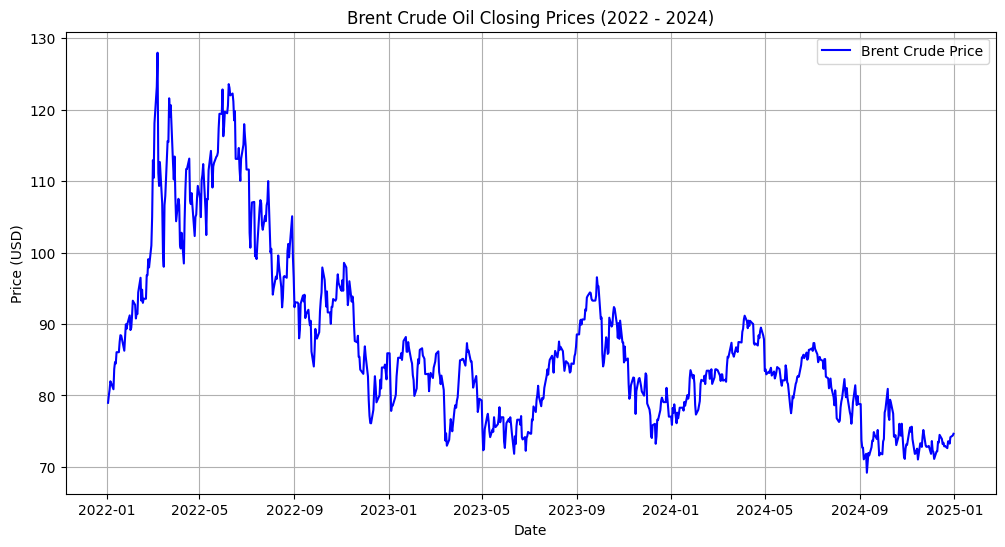

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(price_series, color='blue', label='Brent Crude Price')
plt.title('Brent Crude Oil Closing Prices (2022 - 2024)')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.grid(True)
plt.show()

2. Calculate daily percentage returns.


Date
2022-01-04    0.012915
2022-01-05    0.010000
2022-01-06    0.014728
2022-01-07   -0.002927
2022-01-10   -0.010764
                ...   
2024-12-25    0.000000
2024-12-26   -0.004349
2024-12-27    0.012421
2024-12-30    0.002966
2024-12-31    0.003361
Freq: B, Name: BZ=F, Length: 781, dtype: float64


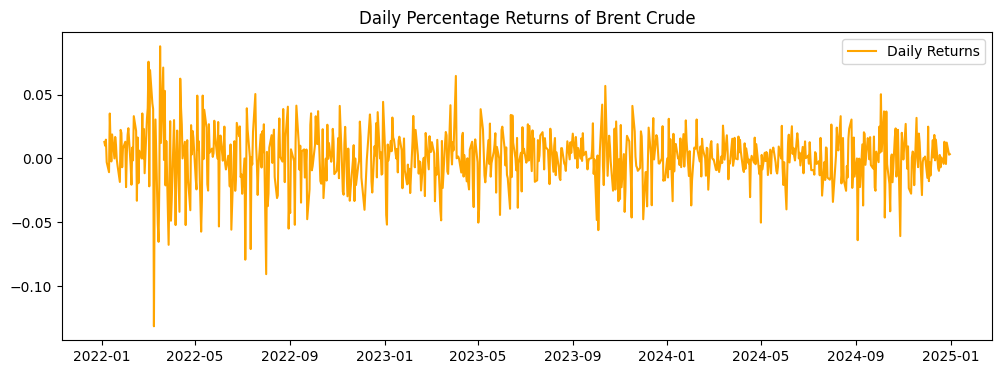

In [ ]:
return_series = price_series.pct_change().dropna()
print(return_series)

# Plot returns
plt.figure(figsize=(12, 4))
plt.plot(return_series, color='orange', label='Daily Returns')
plt.title('Daily Percentage Returns of Brent Crude')
plt.legend()
plt.show()

3. Test both the price series and return series for stationarity using the ADF test.


In [ ]:
from statsmodels.tsa.stattools import adfuller

def perform_adf_test(series, name):
    result = adfuller(series)
    print(f"\n--- ADF Test: {name} ---")
    print(f"ADF Statistic: {result[0]:.4f}")
    print(f"p-value: {result[1]:.4e}")
    if result[1] <= 0.05:
        print("Result: Stationary (Reject Null Hypothesis)")
    else:
        print("Result: Non-Stationary (Fail to Reject Null Hypothesis)")

perform_adf_test(price_series, "Price Series")
perform_adf_test(return_series, "Return Series")


--- ADF Test: Price Series ---
ADF Statistic: -1.4832
p-value: 5.4179e-01
Result: Non-Stationary (Fail to Reject Null Hypothesis)

--- ADF Test: Return Series ---
ADF Statistic: -9.2832
p-value: 1.2355e-15
Result: Stationary (Reject Null Hypothesis)


/tmp/ipykernel_1144/1319427473.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series)
/tmp/ipykernel_1144/1319427473.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series)


4. Plot ACF and PACF for the stationary series.


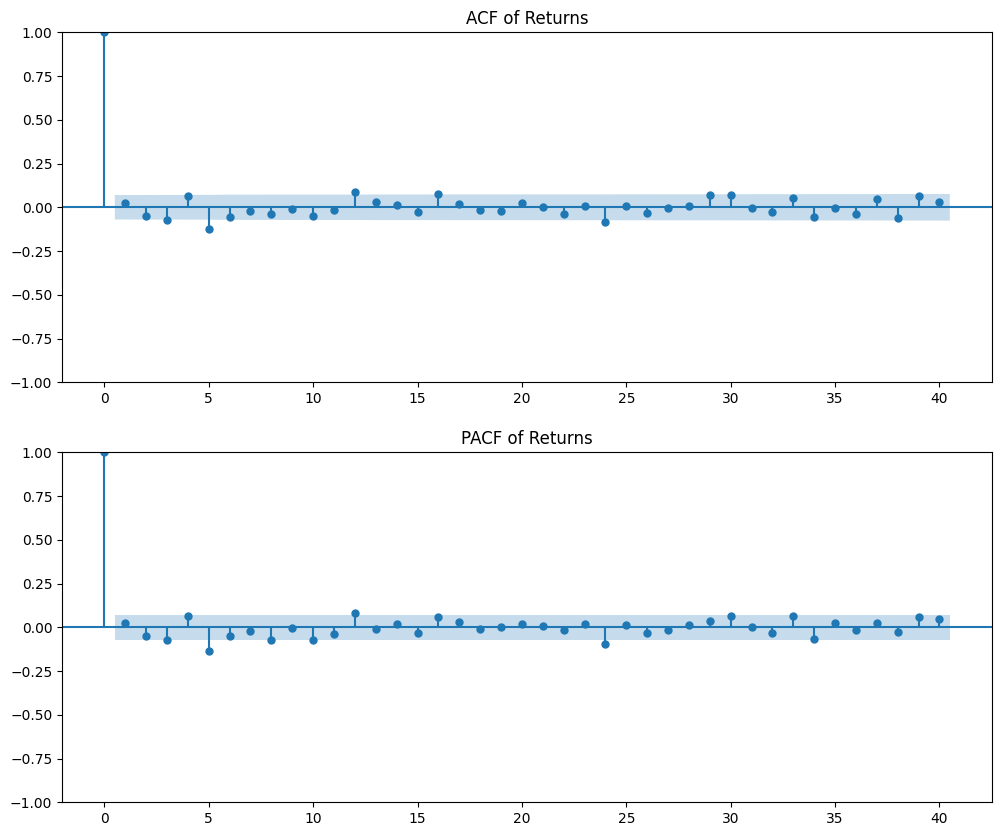

In [ ]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, ax = plt.subplots(2, 1, figsize=(12, 10))
plot_acf(return_series, lags=40, ax=ax[0], title="ACF of Returns")
plot_pacf(return_series, lags=40, ax=ax[1], title="PACF of Returns")
plt.show()

5. Fit suitable:
- AR model
- MA model
- ARMA model
- ARIMA model


In [ ]:
from statsmodels.tsa.arima.model import ARIMA

# AR(1) on returns
model_ar = ARIMA(return_series, order=(1, 0, 0)).fit()

# MA(1) on returns
model_ma = ARIMA(return_series, order=(0, 0, 1)).fit()

# ARMA(1,1) on returns
model_arma = ARIMA(return_series, order=(1, 0, 1)).fit()

# ARIMA(1,1,1) on Price (d=1 handles the non-stationarity)
model_arima = ARIMA(price_series, order=(1, 1, 1)).fit()

6. Compare models using AIC, BIC, RMSE and MAE.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error

metrics = {}

def evaluate_model(model_fit, actual, name, skip=0):
    # skip = number of first fitted values to ignore (1 for d=1 models)
    fitted = model_fit.fittedvalues[skip:]
    actual = actual[skip:]
    metrics[name] = {
        'AIC': model_fit.aic,
        'BIC': model_fit.bic,
        'RMSE': np.sqrt(mean_squared_error(actual, fitted)),
        'MAE': mean_absolute_error(actual, fitted)
    }

evaluate_model(model_ar,    return_series, 'AR(1)')
evaluate_model(model_ma,    return_series, 'MA(1)')
evaluate_model(model_arma,  return_series, 'ARMA(1,1)')
evaluate_model(model_arima, price_series,  'ARIMA(1,1,1)', skip=1)

df_metrics = pd.DataFrame(metrics).T
print(df_metrics)

                      AIC          BIC      RMSE       MAE
AR(1)        -3732.964404 -3718.982679  0.022090  0.016232
MA(1)        -3732.996158 -3719.014432  0.022089  0.016229
ARMA(1,1)    -3733.751956 -3715.109655  0.022050  0.016213
ARIMA(1,1,1)  3376.407024  3390.388750  2.093403  1.454158


7. Perform Ljung–Box residual diagnostics.


In [ ]:
import pandas as pd
from statsmodels.stats.diagnostic import acorr_ljungbox

# Create a list of the fitted models
models = {
    "AR(1)": model_ar,
    "MA(1)": model_ma,
    "ARMA(1,1)": model_arma,
    "ARIMA(1,1,1)": model_arima
}

print("--- Ljung-Box Test Results (Lag 10) ---")
lb_results = []

for name, model in models.items():
    # Perform Ljung-Box test on residuals
    # Drop the first residual: for the ARIMA (d=1) model it equals the whole first price (the first fitted value is 0), which would distort the test
    resids = model.resid.iloc[1:]
    lb_df = acorr_ljungbox(resids, lags=[10], return_df=True)

    lb_stat = lb_df.iloc[0, 0]
    p_val = lb_df.iloc[0, 1]

    lb_results.append({
        "Model": name,
        "LB Stat": f"{lb_stat:.4f}",
        "p-value": f"{p_val:.4e}",
        "Is White Noise?": "Yes (Good)" if p_val > 0.05 else "No (Bad)"
    })

lb_comparison = pd.DataFrame(lb_results)
print(lb_comparison)

--- Ljung-Box Test Results (Lag 10) ---
          Model  LB Stat     p-value Is White Noise?
0         AR(1)  28.3065  1.6121e-03        No (Bad)
1         MA(1)  28.2891  1.6225e-03        No (Bad)
2     ARMA(1,1)  27.0014  2.6030e-03        No (Bad)
3  ARIMA(1,1,1)  27.0072  2.5976e-03        No (Bad)


In [ ]:
# Ljung–Box test (lag 10).
# H₀: the residuals are white noise (no autocorrelation up to lag 10). All four models have p-values between 0.0016 and 0.0026,
# well below 0.05, so H₀ is rejected for every model: some autocorrelation remains in the residuals. ARMA(1,1) on returns and
# ARIMA(1,1,1) on prices give almost identical results (Q ≈ 27.0), because ARIMA(1,1,1) effectively fits an ARMA(1,1) to the
# daily price changes. None of these simple models fully captures the dependence in Brent crude prices.
# Higher-order models, or models for the changing volatility of oil prices (e.g. GARCH), could improve this.

8. Plot actual versus fitted values.


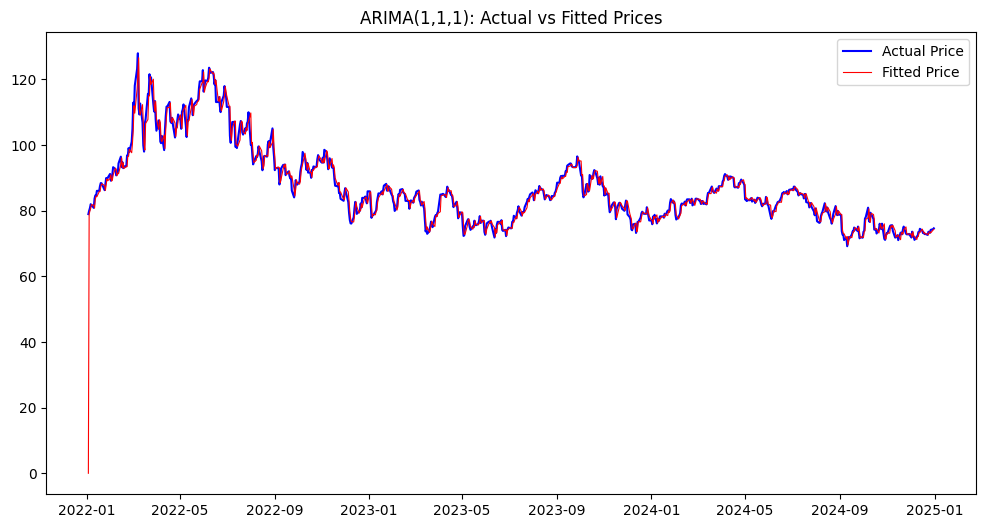

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(price_series, label='Actual Price', color='blue')
plt.plot(model_arima.fittedvalues, label='Fitted Price', color='red', linewidth=0.8)
plt.title('ARIMA(1,1,1): Actual vs Fitted Prices')
plt.legend()
plt.show()

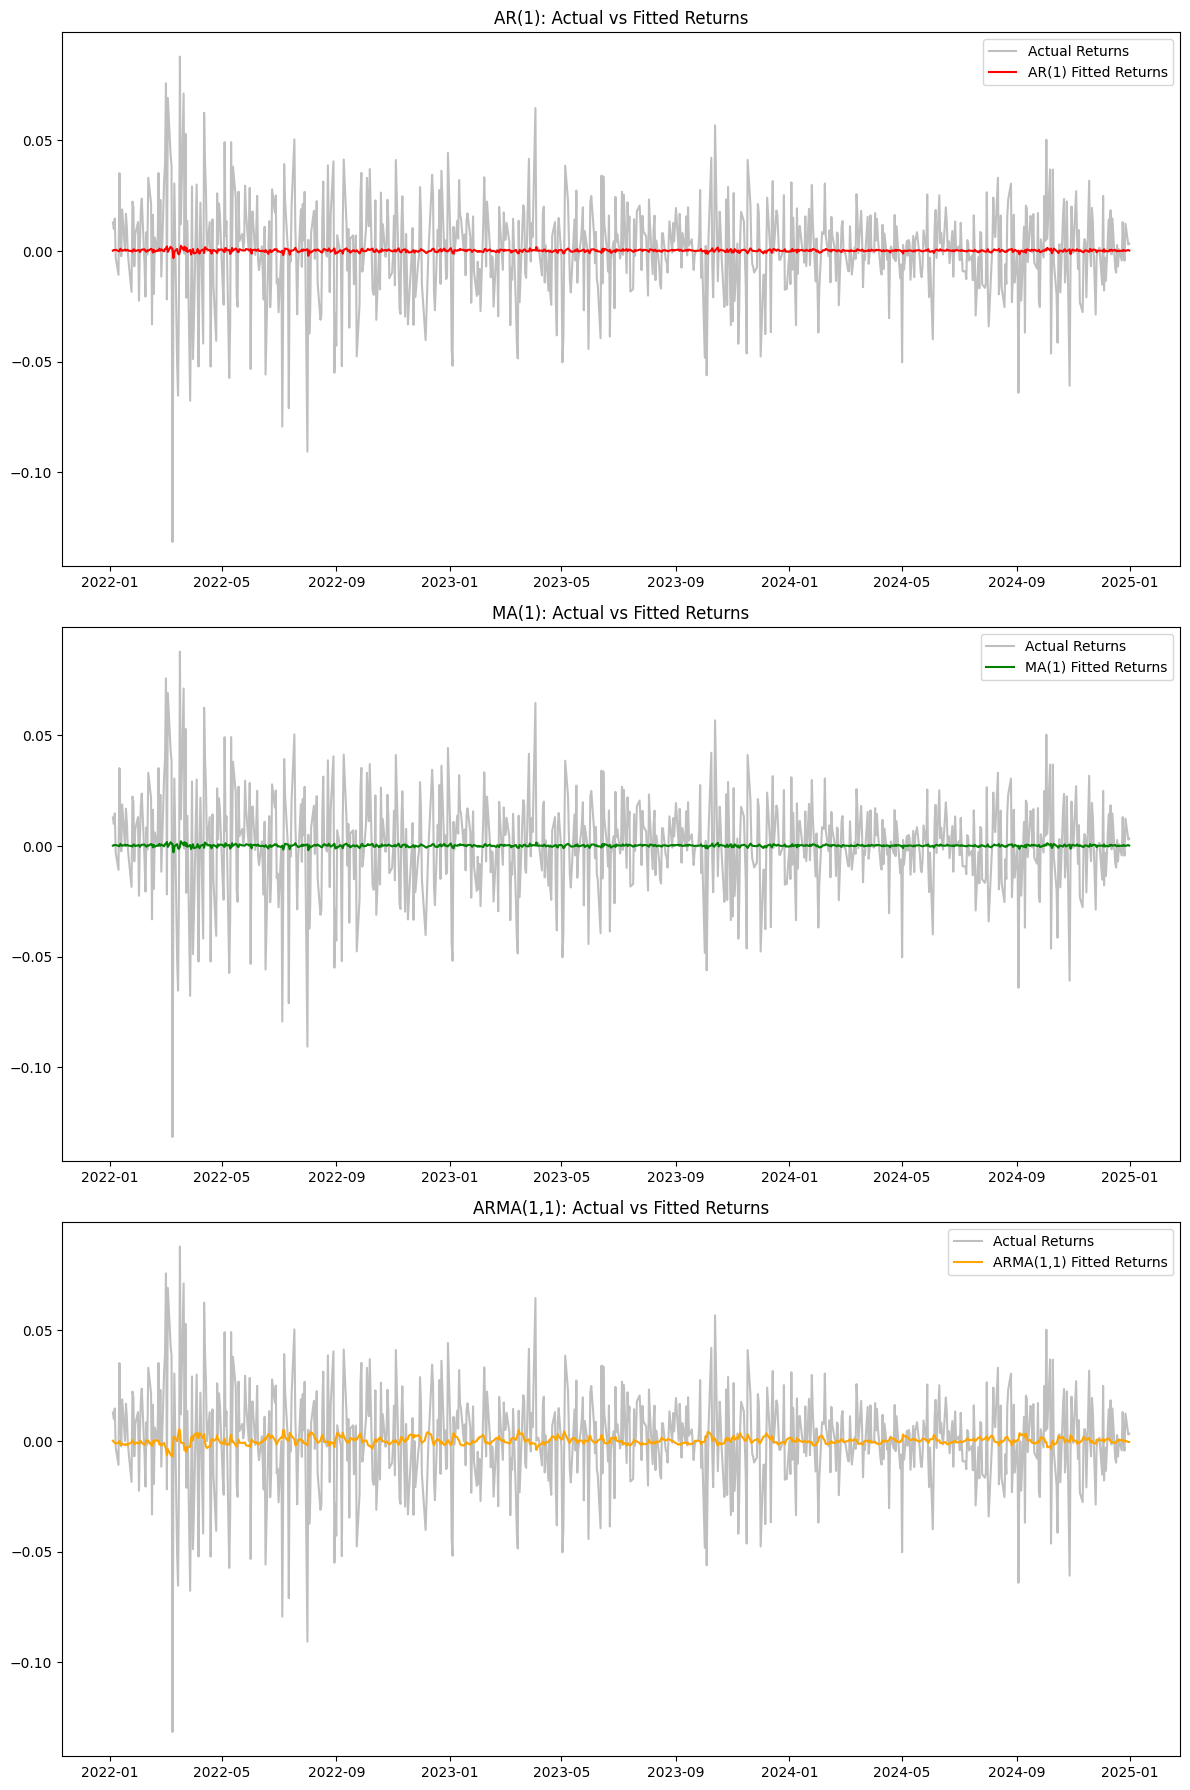

In [ ]:
# Create a figure with 3 subplots
fig, axes = plt.subplots(3, 1, figsize=(12, 18))

# 1. AR(1) Model Plot (Returns)
axes[0].plot(return_series, label='Actual Returns', color='gray', alpha=0.5)
axes[0].plot(model_ar.fittedvalues, label='AR(1) Fitted Returns', color='red')
axes[0].set_title('AR(1): Actual vs Fitted Returns')
axes[0].legend()

# 2. MA(1) Model Plot (Returns)
axes[1].plot(return_series, label='Actual Returns', color='gray', alpha=0.5)
axes[1].plot(model_ma.fittedvalues, label='MA(1) Fitted Returns', color='green')
axes[1].set_title('MA(1): Actual vs Fitted Returns')
axes[1].legend()

# 3. ARMA(1,1) Model Plot (Returns)
axes[2].plot(return_series, label='Actual Returns', color='gray', alpha=0.5)
axes[2].plot(model_arma.fittedvalues, label='ARMA(1,1) Fitted Returns', color='orange')
axes[2].set_title('ARMA(1,1): Actual vs Fitted Returns')
axes[2].legend()

plt.tight_layout()
plt.show()

In [ ]:
print(model_ar.params)
print(model_ma.params)
print(model_arma.summary())

const     0.000172
ar.L1     0.025454
sigma2    0.000488
dtype: float64
const     0.000172
ma.L1     0.022435
sigma2    0.000488
dtype: float64
                               SARIMAX Results                                
Dep. Variable:                   BZ=F   No. Observations:                  781
Model:                 ARIMA(1, 0, 1)   Log Likelihood                1870.876
Date:                Mon, 28 Sep 2026   AIC                          -3733.752
Time:                        16:51:25   BIC                          -3715.110
Sample:                    01-04-2022   HQIC                         -3726.582
                         - 12-31-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0002      0.001      0.237      0.813      -0.001

In [ ]:
# The fitted returns stay near zero because the AR(1) and MA(1) coefficients are tiny (≈0.02), and in ARMA(1,1) the AR (0.70) and MA (−0.75)
# terms almost cancel each other out. So past returns explain very little of the next day's return, which is typical of financial data.

9. Forecast crude oil prices for the next 20 trading days.

In [ ]:
# Define forecast horizon
forecast_steps = 20

# --- ARIMA Forecast (on Prices) ---
arima_forecast_obj = model_arima.get_forecast(steps=forecast_steps)
arima_mean = arima_forecast_obj.predicted_mean
arima_ci = arima_forecast_obj.conf_int()

# --- ARMA Forecast (on Returns) ---
arma_forecast_obj = model_arma.get_forecast(steps=forecast_steps)
arma_return_forecast = arma_forecast_obj.predicted_mean

# Convert ARMA returns back to price levels
last_price = price_series.iloc[-1]
arma_price_forecast = []
temp_price = last_price

for r in arma_return_forecast:
    temp_price = temp_price * (1 + r)
    arma_price_forecast.append(temp_price)

# Create a date index for the next 20 business days
forecast_index = pd.date_range(start=price_series.index[-1], periods=forecast_steps + 1, freq='B')[1:]
arma_price_forecast = pd.Series(arma_price_forecast, index=forecast_index)
arima_mean.index = forecast_index
arima_ci.index = forecast_index

print("ARIMA 20-Day Price Forecast:")
print(arima_mean)

ARIMA 20-Day Price Forecast:
2025-01-01    74.571031
2025-01-02    74.512916
2025-01-03    74.463946
2025-01-06    74.422682
2025-01-07    74.387911
2025-01-08    74.358612
2025-01-09    74.333923
2025-01-10    74.313120
2025-01-13    74.295590
2025-01-14    74.280818
2025-01-15    74.268372
2025-01-16    74.257883
2025-01-17    74.249046
2025-01-20    74.241598
2025-01-21    74.235323
2025-01-22    74.230036
2025-01-23    74.225580
2025-01-24    74.221825
2025-01-27    74.218662
2025-01-28    74.215996
Freq: B, Name: predicted_mean, dtype: float64


10. Plot the forecasts with confidence intervals.

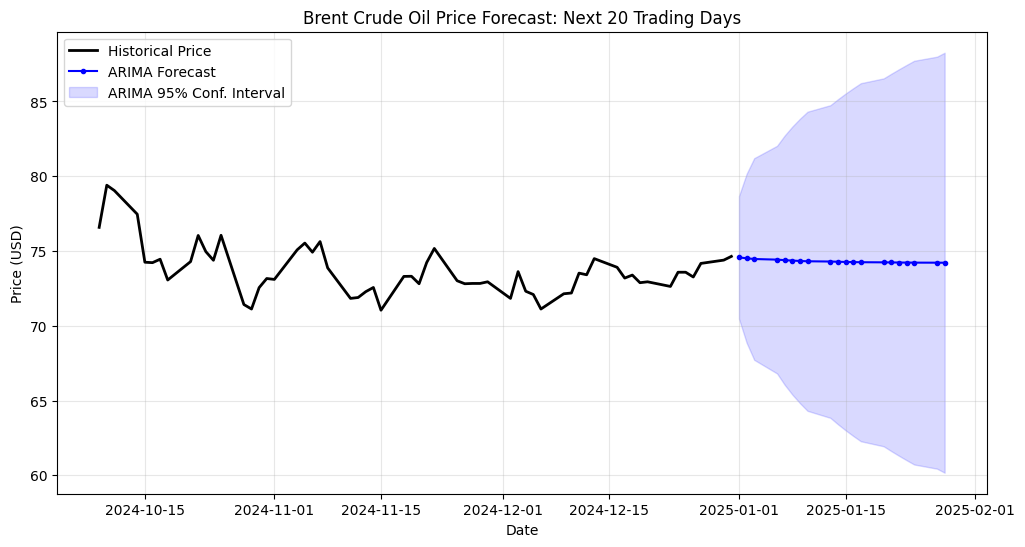

In [ ]:
plt.figure(figsize=(12, 6))

# Plot the last 60 days of historical data for context
plt.plot(price_series.iloc[-60:], label='Historical Price', color='black', linewidth=2)

# Plot ARIMA Forecast
plt.plot(arima_mean, label='ARIMA Forecast', color='blue', marker='o', markersize=3)

# Plot ARIMA Confidence Interval
plt.fill_between(forecast_index,
                 arima_ci.iloc[:, 0],
                 arima_ci.iloc[:, 1],
                 color='blue', alpha=0.15, label='ARIMA 95% Conf. Interval')

plt.title(f'Brent Crude Oil Price Forecast: Next {forecast_steps} Trading Days')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.show()

11. Compare the forecasting performance of ARMA and ARIMA models.

In [ ]:
# last_price = train_p.iloc[-1]            # last price in the training data
# arma_prices = []

# for r in arma_r:                         # arma_r = the 20 forecast returns
#     last_price = last_price * (1 + r)    # tomorrow's price = today's price x (1 + return)
#     arma_prices.append(last_price)

# arma_f = pd.Series(arma_prices, index=test_p.index)

In [ ]:
# compare ARMA and ARIMA forecasts on the last 20 days
train_p, test_p = price_series[:-20], price_series[-20:]

# ARMA(1,1) on returns -> converted back to prices
train_r = train_p.pct_change().dropna()
arma_r = ARIMA(train_r, order=(1, 0, 1)).fit().forecast(20)
arma_data = float(train_p.iloc[-1]) * (1 + arma_r.values).cumprod()
arma_f = pd.Series(arma_data, index=test_p.index)

# ARIMA(1,1,1) on prices
arima_f = ARIMA(train_p, order=(1, 1, 1)).fit().forecast(20)
arima_f.index = test_p.index

print("--- FORECAST PERFORMANCE ON THE LAST 20 DAYS ---")
for name, f in [("ARMA(1,1) on returns", arma_f), ("ARIMA(1,1,1) on prices", arima_f)]:
    rmse = np.sqrt(mean_squared_error(test_p, f))
    mae = mean_absolute_error(test_p, f)
    mape = np.mean(np.abs((test_p - f) / test_p)) * 100
    print(f"{name:24s} RMSE = {rmse:.4f}   MAE = {mae:.4f}   MAPE = {mape:.2f}%")

--- FORECAST PERFORMANCE ON THE LAST 20 DAYS ---
ARMA(1,1) on returns     RMSE = 0.9760   MAE = 0.7601   MAPE = 1.05%
ARIMA(1,1,1) on prices   RMSE = 0.9732   MAE = 0.7524   MAPE = 1.03%


In [ ]:
# ARIMA(1,1,1) is better!

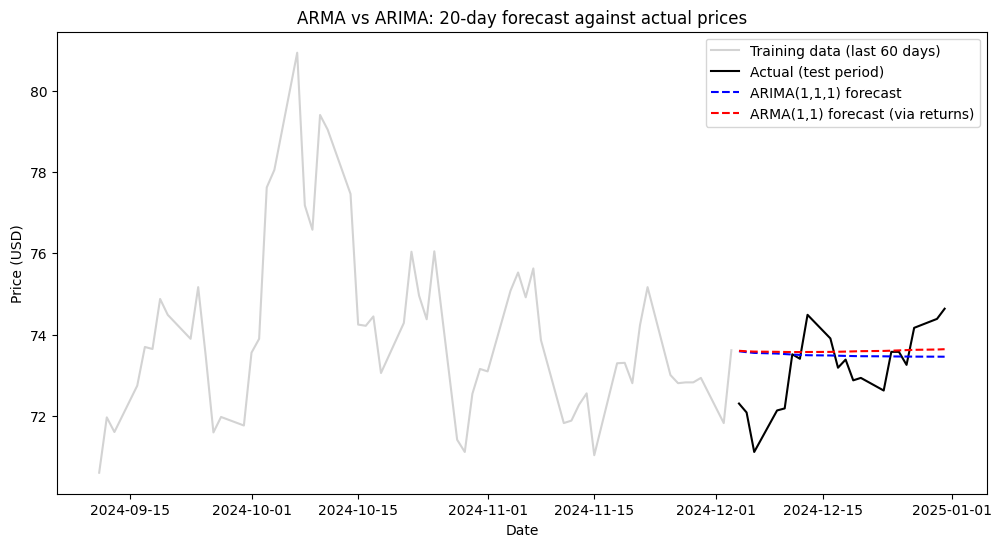

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(train_p[-60:], label="Training data (last 60 days)", color='lightgray')
plt.plot(test_p, label="Actual (test period)", color='black')
plt.plot(arima_f, label="ARIMA(1,1,1) forecast", color='blue', ls='--')
plt.plot(arma_f, label="ARMA(1,1) forecast (via returns)", color='red', ls='--')
plt.title("ARMA vs ARIMA: 20-day forecast against actual prices")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.show()

In [ ]:
# Both forecasts are essentially flat at the last observed price, while the actual price fluctuates around them (≈ $71–75).
# This confirms that neither model can predict short-term price direction; both behave like a random-walk forecast.

#Q2

Obtain the electricity demand data for India for the period 1 January 2024 to 31 December 2024 from an official Indian power-sector data source such as the National Power Portal (NPP)/GRID-INDIA. Use the available time-block observations to construct a daily electricity-demand time series. Use January 2024 - June 2025.xlsx file in https://data.mendeley.com/datasets/y58jknpgs8/2

Perform:


In [ ]:
import pandas as pd

data = pd.read_excel('/content/drive/MyDrive/Math_Modelling_lab/January 2024- June 2025.xlsx')

print(data.info())

data

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12990 entries, 0 to 12989
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Timestamp              12990 non-null  object
 1   Demand (MW)            12990 non-null  object
 2   Wind (MW)              12990 non-null  object
 3   Solar (MW)             12990 non-null  object
 4   Total Generation (MW)  12990 non-null  object
dtypes: object(5)
memory usage: 507.6+ KB
None


,Timestamp,Demand (MW),Wind (MW),Solar (MW),Total Generation (MW)
0,01-01-2024 00:00:00,141981.26,9545.07,20.29,142193.38
1,01-01-2024 01:00:00,138675.49,9027.05,19.96,138792.04
2,01-01-2024 02:00:00,136122.78,8241.48,19.79,136796.02
3,01-01-2024 03:00:00,135806.51,7866.09,19.73,136859.67
4,01-01-2024 04:00:00,139905.77,7430.71,20.02,140561.49
...,...,...,...,...,...
12985,Timestamp,16-01-2024 17:06:41,16-01-2024 17:06:41,2024-09-02 18:52:22,16-01-2024 17:06:41
12986,Maximum,291851.75,34721.52,65480.24,259788.95
12987,Timestamp,18-09-2024 09:02:25,2024-02-05 14:58:36,30-03-2025 12:09:37,18-05-2024 16:42:41
12988,Average,194009.98,8894.01,15623.69,196299.98


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Remove the summary rows from the bottom
df = data.iloc[:-6].copy()

# Convert multiple columns to numeric
cols_to_fix = ['Demand (MW)', 'Wind (MW)', 'Solar (MW)', 'Total Generation (MW)']
df[cols_to_fix] = df[cols_to_fix].apply(pd.to_numeric, errors='coerce')

# Convert Timestamp
df['Timestamp'] = pd.to_datetime(df['Timestamp'], dayfirst=True, errors='coerce')
df = df.dropna(subset=['Timestamp'] + cols_to_fix)

# Set Index
df = df.set_index('Timestamp').sort_index()

df_full = df.copy()                          # keep Jan-Jun 2025 to check the forecast later
df = df.loc['2024-01-01':'2024-12-31']       # the question asks for 1 January 2024 to 31 December 2024 only

print(df.info())
df

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 8784 entries, 2024-01-01 00:00:00 to 2024-12-31 23:00:00
Data columns (total 4 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Demand (MW)            8784 non-null   float64
 1   Wind (MW)              8784 non-null   float64
 2   Solar (MW)             8784 non-null   float64
 3   Total Generation (MW)  8784 non-null   float64
dtypes: float64(4)
memory usage: 343.1 KB
None


,Demand (MW),Wind (MW),Solar (MW),Total Generation (MW)
Timestamp,,,,
2024-01-01 00:00:00,141981.26,9545.07,20.29,142193.38
2024-01-01 01:00:00,138675.49,9027.05,19.96,138792.04
2024-01-01 02:00:00,136122.78,8241.48,19.79,136796.02
2024-01-01 03:00:00,135806.51,7866.09,19.73,136859.67
2024-01-01 04:00:00,139905.77,7430.71,20.02,140561.49
...,...,...,...,...
2024-12-31 19:00:00,190898.67,7161.99,554.33,194416.96
2024-12-31 20:00:00,177358.79,9013.22,117.97,180263.17
2024-12-31 21:00:00,166053.19,10269.73,73.72,169515.42


1. Plot the hourly electricity demand series

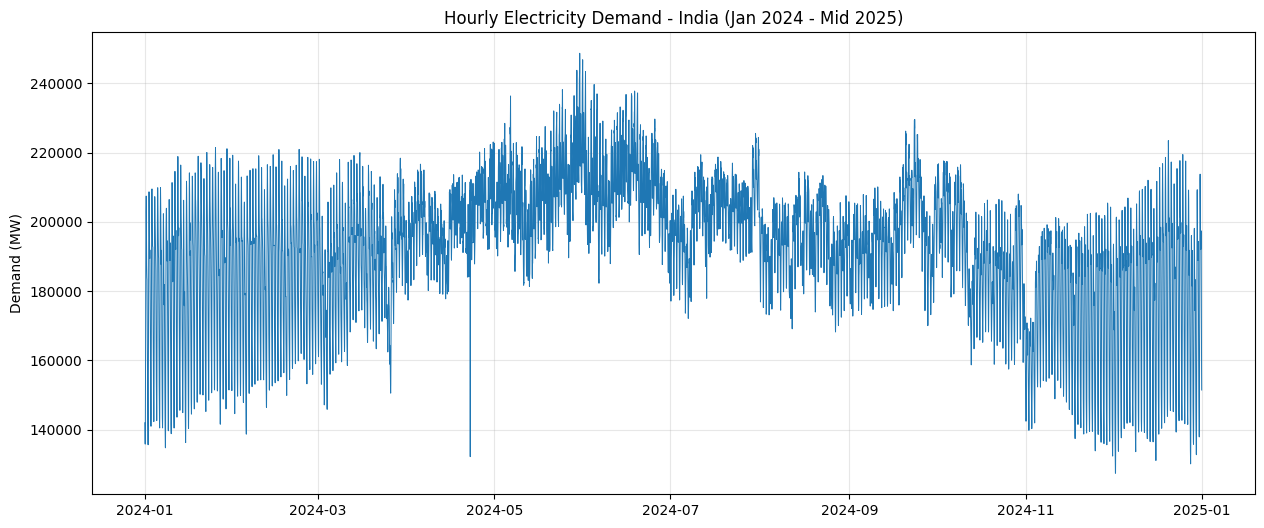

In [ ]:
plt.figure(figsize=(15, 6))
plt.plot(df['Demand (MW)'], linewidth=0.7)
plt.title('Hourly Electricity Demand - India (Jan 2024 - Mid 2025)')
plt.ylabel('Demand (MW)')
plt.grid(True, alpha=0.3)
plt.show()

2. Identify daily and weekly seasonal patterns.

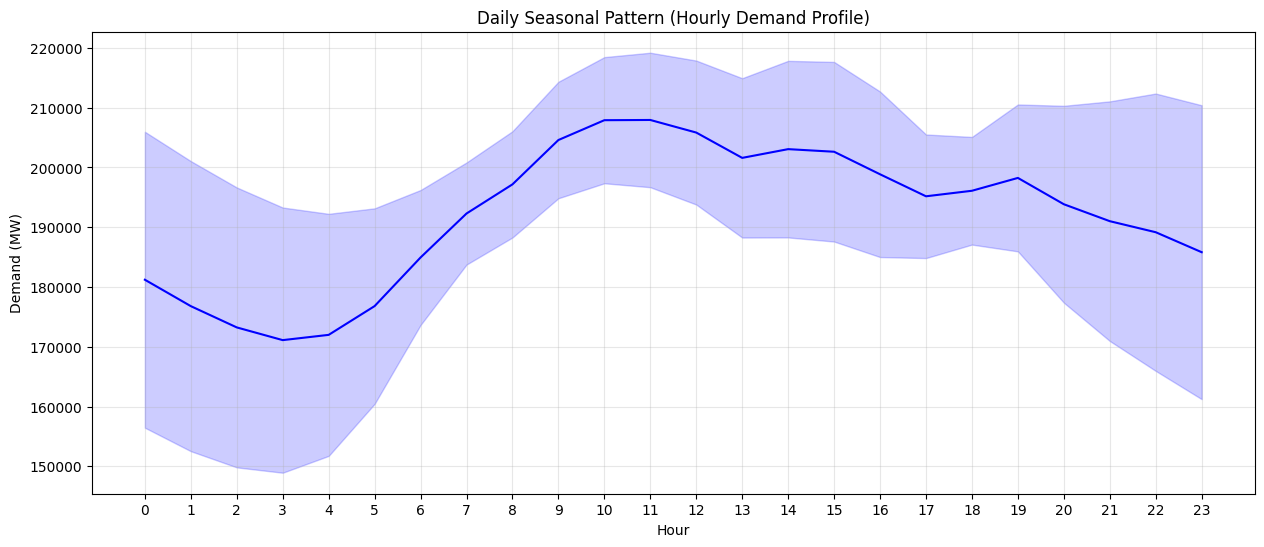

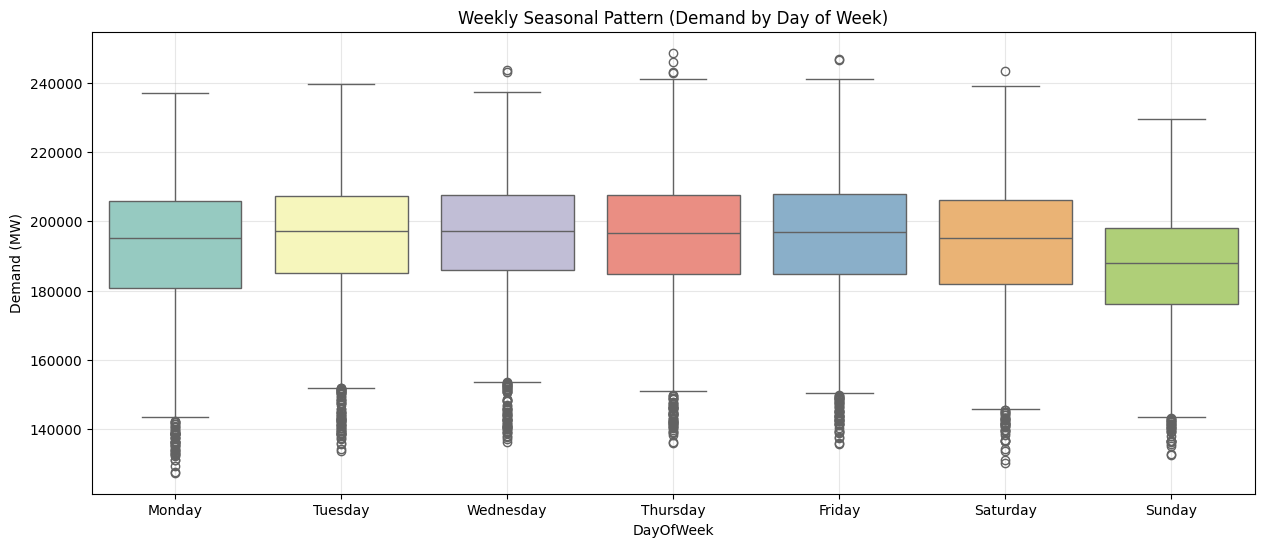

In [ ]:
# Create temporary columns for seasonality analysis
df_seasonal = df.copy()
df_seasonal['Hour'] = df_seasonal.index.hour
df_seasonal['DayOfWeek'] = df_seasonal.index.day_name()

# Set order for days
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# Daily Pattern: How demand changes hour-by-hour
plt.figure(figsize=(15, 6))
sns.lineplot(data=df_seasonal, x='Hour', y='Demand (MW)', color='blue', errorbar='sd')
plt.title('Daily Seasonal Pattern (Hourly Demand Profile)')
plt.xticks(range(0, 24))
plt.grid(True, alpha=0.3)
plt.show()

# Weekly Pattern: How demand changes day-by-day
plt.figure(figsize=(15, 6))
sns.boxplot(data=df_seasonal, x='DayOfWeek', y='Demand (MW)', order=day_order, palette='Set3', hue='DayOfWeek', legend=False)
plt.title('Weekly Seasonal Pattern (Demand by Day of Week)')
plt.grid(True, alpha=0.3)
plt.show()

3. Aggregate the data into daily electricity demand.


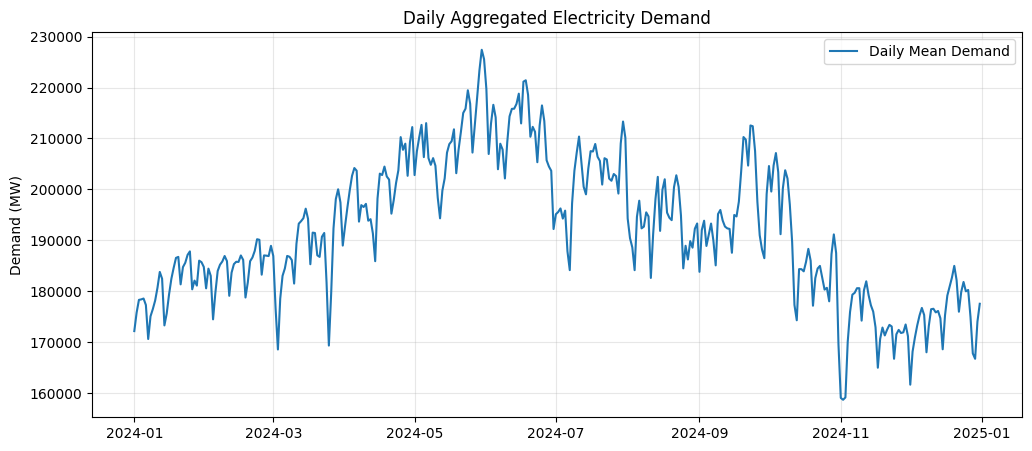

In [ ]:
daily_demand = df['Demand (MW)'].resample('D').mean().dropna()

plt.figure(figsize=(12, 5))
plt.plot(daily_demand, label='Daily Mean Demand')
plt.title('Daily Aggregated Electricity Demand')
plt.ylabel('Demand (MW)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

4. Test the series for stationarity using the ADF test.

In [ ]:
from statsmodels.tsa.stattools import adfuller

def perform_adf_test(series, name):
    result = adfuller(series)
    print(f"--- ADF Test: {name} ---")
    print(f"ADF Statistic: {result[0]:.4f}")
    print(f"p-value: {result[1]:.4f}")
    if result[1] <= 0.05:
        print("Result: Stationary")
    else:
        print("Result: Non-Stationary (Differencing Needed)")

perform_adf_test(daily_demand, "Original Daily Series")

--- ADF Test: Original Daily Series ---
ADF Statistic: -1.3007
p-value: 0.6289
Result: Non-Stationary (Differencing Needed)


/tmp/ipykernel_1144/2566972252.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series)


5. Apply differencing where necessary.


In [ ]:
daily_diff = daily_demand.diff().dropna()
perform_adf_test(daily_diff, "1st Order Differenced Series")

--- ADF Test: 1st Order Differenced Series ---
ADF Statistic: -6.4470
p-value: 0.0000
Result: Stationary


/tmp/ipykernel_1144/2566972252.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series)


6. Examine ACF and PACF plots.


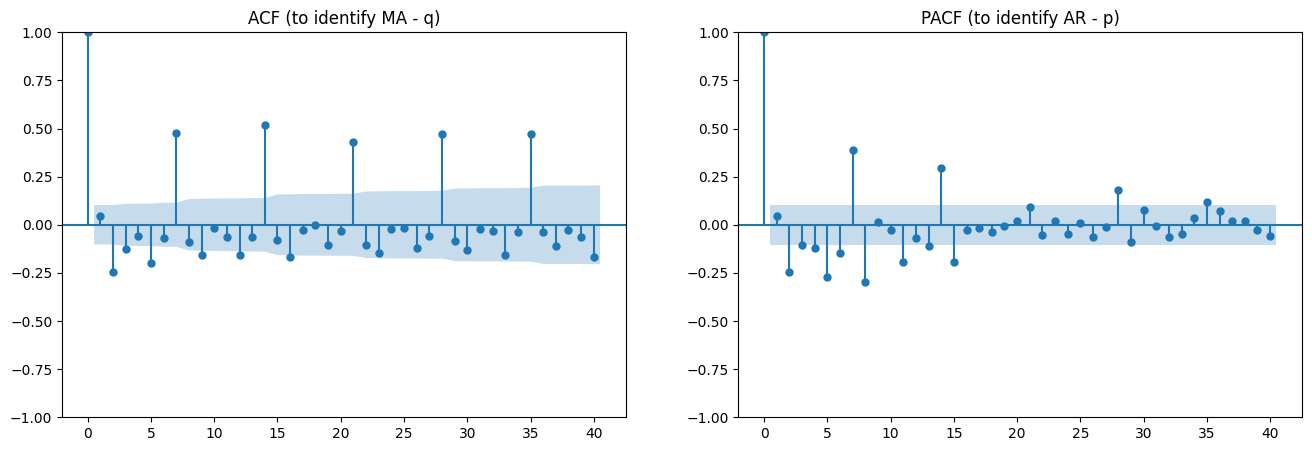

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Use the stationary differenced series
plot_acf(daily_diff, lags=40, ax=ax1)
plot_pacf(daily_diff, lags=40, ax=ax2)

ax1.set_title("ACF (to identify MA - q)")
ax2.set_title("PACF (to identify AR - p)")
plt.show()

7. Fit an ARIMA model.
8. Develop a Seasonal ARIMA (SARIMA) model to account for weekly seasonality.


In [ ]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

# By NOT providing a seasonal_order, it behaves as a standard ARIMA
model_arima = SARIMAX(daily_demand, order=(1, 1, 1)).fit(disp=False)

# Here we add the seasonal_order for the weekly (7-day) cycle
model_sarima = SARIMAX(daily_demand,
                       order=(1, 1, 1),
                       seasonal_order=(1, 1, 1, 7)).fit(disp=False)

print("ARIMA and SARIMA models have been fitted.")

ARIMA and SARIMA models have been fitted.


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


9. Compare Models (AIC, BIC, RMSE, MAE)

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

def get_metrics(model_fit, actual, name):
    burn = max(model_fit.loglikelihood_burn, 1)   # 1 for ARIMA, 8 for SARIMA
    fitted = model_fit.fittedvalues[burn:]
    actual = actual[burn:]
    return {
        "Model": name,
        "AIC": model_fit.aic,
        "BIC": model_fit.bic,
        "RMSE": np.sqrt(mean_squared_error(actual, fitted)),
        "MAE": mean_absolute_error(actual, fitted)
    }

metrics_arima = get_metrics(model_arima, daily_demand, "ARIMA(1,1,1)")
metrics_sarima = get_metrics(model_sarima, daily_demand, "SARIMA(1,1,1)(1,1,1,7)")

comparison_df = pd.DataFrame([metrics_arima, metrics_sarima])
comparison_df

,Model,AIC,BIC,RMSE,MAE
0,"ARIMA(1,1,1)",7266.338412,7278.038105,5047.646479,3897.953488
1,"SARIMA(1,1,1)(1,1,1,7)",7045.297359,7064.700024,4484.802126,3246.615726


10. Perform residual diagnostics.


--- ARIMA(1,1,1): Ljung-Box test ---
       lb_stat     lb_pvalue
7   122.640089  2.158972e-23
14  248.176174  6.848839e-45 



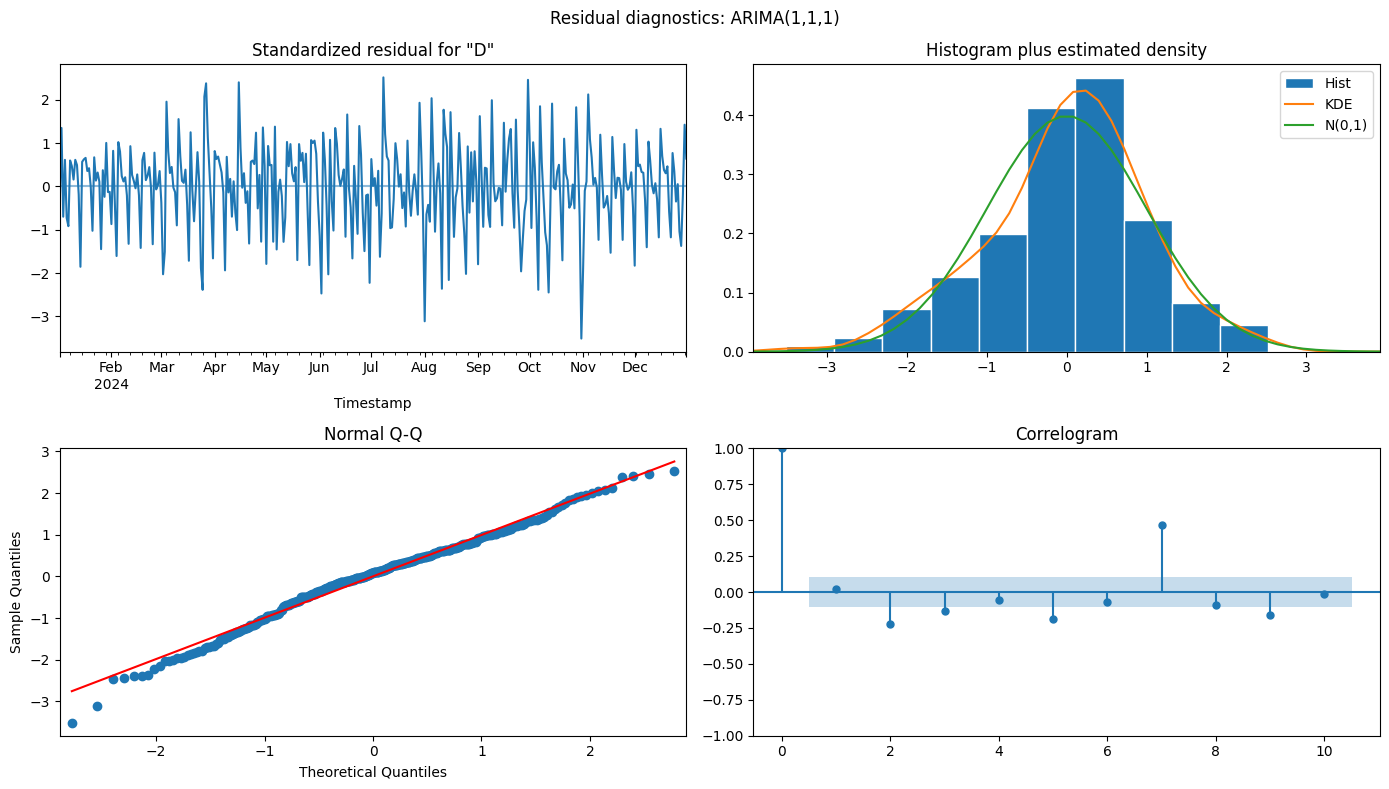

--- SARIMA(1,1,1)(1,1,1,7): Ljung-Box test ---
      lb_stat     lb_pvalue
7   57.542084  4.663715e-10
14  80.962566  1.875055e-11 



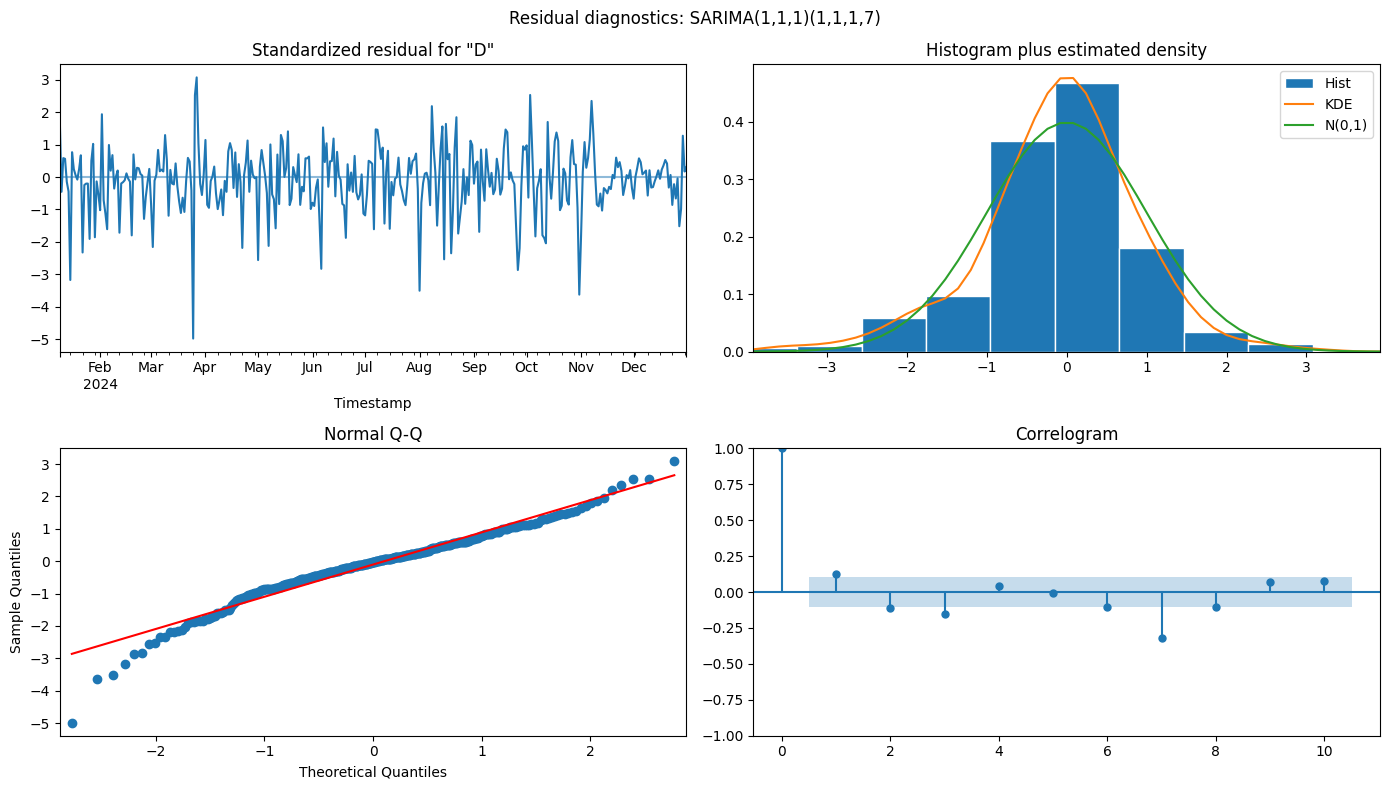

In [ ]:
from statsmodels.stats.diagnostic import acorr_ljungbox

for name, m in [("ARIMA(1,1,1)", model_arima), ("SARIMA(1,1,1)(1,1,1,7)", model_sarima)]:
    resids = m.resid[m.loglikelihood_burn:]
    lb = acorr_ljungbox(resids, lags=[7, 14], return_df=True)   # used lags 7 and 14 because these are the weekly lags (weekly and biweekly)
    print(f"--- {name}: Ljung-Box test ---")
    print(lb, "\n")

    m.plot_diagnostics(figsize=(14, 8))
    plt.suptitle(f"Residual diagnostics: {name}")
    plt.tight_layout()
    plt.show()

11. Forecast electricity demand for the next 14 days.

In [ ]:
actual_jan = df_full['Demand (MW)'].resample('D').mean()['2025-01-01':'2025-01-14']

# 14-day forecasts with 95% confidence intervals
arima_fc = model_arima.get_forecast(steps=14)
sarima_fc = model_sarima.get_forecast(steps=14)

arima_mean, arima_ci = arima_fc.predicted_mean, arima_fc.conf_int()
sarima_mean, sarima_ci = sarima_fc.predicted_mean, sarima_fc.conf_int()

for name, fc in [("ARIMA", arima_mean), ("SARIMA", sarima_mean)]:
    rmse = np.sqrt(mean_squared_error(actual_jan, fc))
    mae = mean_absolute_error(actual_jan, fc)
    mape = np.mean(np.abs((actual_jan.values - fc.values) / actual_jan.values)) * 100
    print(f"{name:7s} forecast vs actual (1-14 Jan 2025): RMSE = {rmse:,.0f}  MAE = {mae:,.0f}  MAPE = {mape:.2f}%")

ARIMA   forecast vs actual (1-14 Jan 2025): RMSE = 9,231  MAE = 6,491  MAPE = 3.42%
SARIMA  forecast vs actual (1-14 Jan 2025): RMSE = 12,540  MAE = 10,578  MAPE = 5.66%


12. Plot actual demand, fitted values and forecasts.


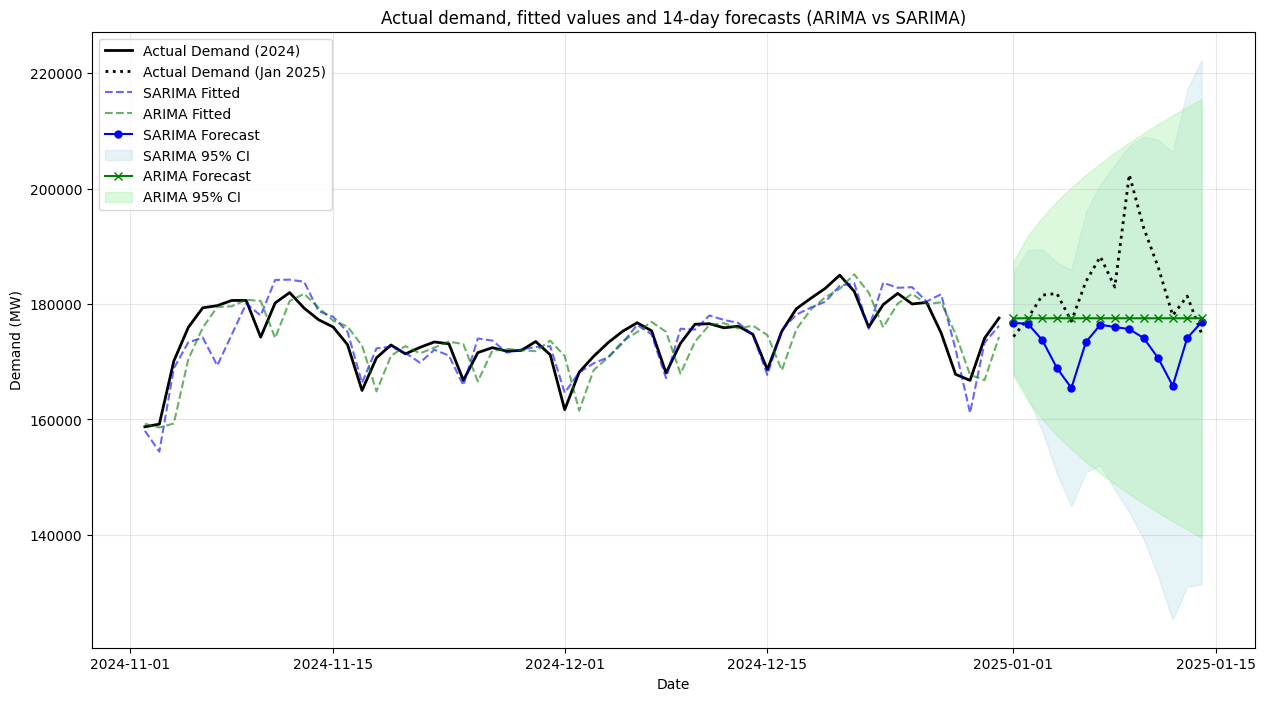

In [ ]:
plt.figure(figsize=(15, 8))

# Actual demand
plt.plot(daily_demand.iloc[-60:], label='Actual Demand (2024)', color='black', linewidth=2)
plt.plot(actual_jan, label='Actual Demand (Jan 2025)', color='black', linestyle=':', linewidth=2)

# Fitted values (last 60 days of 2024)
plt.plot(model_sarima.fittedvalues.iloc[-60:], label='SARIMA Fitted', color='blue', linestyle='--', alpha=0.6)
plt.plot(model_arima.fittedvalues.iloc[-60:], label='ARIMA Fitted', color='green', linestyle='--', alpha=0.6)

# Forecasts with 95% confidence intervals
plt.plot(sarima_mean, label='SARIMA Forecast', color='blue', marker='o', markersize=5)
plt.fill_between(sarima_mean.index, sarima_ci.iloc[:, 0], sarima_ci.iloc[:, 1],
                 color='lightblue', alpha=0.3, label='SARIMA 95% CI')

plt.plot(arima_mean, label='ARIMA Forecast', color='green', marker='x')
plt.fill_between(arima_mean.index, arima_ci.iloc[:, 0], arima_ci.iloc[:, 1],
                 color='lightgreen', alpha=0.3, label='ARIMA 95% CI')

plt.title('Actual demand, fitted values and 14-day forecasts (ARIMA vs SARIMA)')
plt.xlabel('Date')
plt.ylabel('Demand (MW)')
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
# Interpretation: ARIMA(1,1,1) produces a flat forecast (≈ 177,500 MW) and ignores the weekly cycle. SARIMA(1,1,1)(1,1,1,7) reproduces the
# weekly pattern, with forecast dips on Sundays (5 and 12 January), and its fitted values track the weekly ups and downs of 2024 more closely, matching
# its lower RMSE and MAE. SARIMA's confidence interval is wider and widens faster, because it also carries uncertainty about the seasonal pattern.

# In January 2025, actual demand rose well above both forecasts (peaking near 200,000 MW), probably due to a winter cold spell that neither model
# could anticipate from past data alone. So SARIMA is the better model for capturing weekly seasonality, but external factors such as temperature would
# be needed to predict such demand surges.

#Q3

3. Obtain the monthly domestic passenger traffic data of Hyderabad Airport for the period January 2019 to December 2024 from the OpenCity Hyderabad Aviation Traffic Dataset, sourced from the Directorate General of Civil Aviation (DGCA): Hyderabad Aviation Traffic Dataset – OpenCity. Combine the yearly data files, preprocess the data by handling missing observations and arranging the observations chronologically, and construct a monthly time series of total passenger traffic using the appropriate passenger variables. Plot the original time series and calculate the 3-month, 6-month and 12-month moving averages and compare their smoothing effects. Perform the Augmented Dickey-Fuller (ADF) test and apply appropriate differencing to obtain a stationary series. Plot the ACF and PACF and use them to identify suitable orders for AR, MA and ARMA models. Develop suitable AR, MA, ARMA and ARIMA models, and further develop a SARIMA model with a seasonal period of 12 months to account for possible annual seasonality. Compare the models using AIC, BIC, RMSE and MAE, perform residual analysis using residual plots, residual ACF and identify the best-fitting model. Finally, use the selected model to forecast the monthly passenger traffic for the next 12 months, plot the historical data, fitted values and forecasts with 95% confidence intervals, and justify the choice of the final model based on its statistical performance and forecasting accuracy.

Load and Combine CSVs

In [2]:
import os
import pandas as pd

path = '/content/drive/MyDrive/Math_Modelling_lab/Traffic_data_Hyd_airport'

df_list = []
for filename in os.listdir(path):
    filepath = os.path.join(path, filename)
    temp_df = pd.read_csv(filepath)
    df_list.append(temp_df)

# Combine into one DataFrame
df = pd.concat(df_list, axis=0, ignore_index=True)
df

,Year,Month,Origin,Dest,Pax From Origin,Pax To Origin,Freight From Origin,Frieght To Origin,Mail From Origin,Mail To Origin
0,2019,5,HYDERABAD,AGARTALA,222.0,758.0,0.26,0.00,0.00,0.00
1,2019,6,HYDERABAD,AGARTALA,471.0,486.0,1.32,0.00,0.00,0.00
2,2019,1,HYDERABAD,AHMEDABAD,36151.0,35967.0,77.31,168.30,0.05,1.23
3,2019,2,HYDERABAD,AHMEDABAD,32377.0,31931.0,65.16,162.27,0.00,1.17
4,2019,3,HYDERABAD,AHMEDABAD,34003.0,33528.0,114.58,179.47,0.05,0.98
...,...,...,...,...,...,...,...,...,...,...
4004,2024,8,HYDERABAD,VISAKHAPATNAM,35978.0,35581.0,36.09,33.52,13.78,0.00
4005,2024,9,HYDERABAD,VISAKHAPATNAM,33777.0,33258.0,43.46,23.87,9.09,0.00
4006,2024,10,HYDERABAD,VISAKHAPATNAM,44927.0,39766.0,57.24,28.59,12.05,0.00
4007,2024,11,HYDERABAD,VISAKHAPATNAM,40491.0,43074.0,40.25,45.98,22.53,0.00


Preprocessing & Aggregation

In [3]:
df = df.dropna(subset=['Pax From Origin', 'Pax To Origin'])

# Ensure columns are numeric
df['Pax From Origin'] = pd.to_numeric(df['Pax From Origin'], errors='coerce').fillna(0)
df['Pax To Origin'] = pd.to_numeric(df['Pax To Origin'], errors='coerce').fillna(0)

# Calculate Total Passengers per row
df['Total_Pax'] = df['Pax From Origin'] + df['Pax To Origin']

# Create Date column
df['Date'] = pd.to_datetime(df[['Year', 'Month']].assign(DAY=1))

# AGGREGATE: Sum all traffic for each month
traffic_series = df.groupby('Date')['Total_Pax'].sum()

# Set Frequency: 'MS' (Month Start)
traffic_series = traffic_series.asfreq('MS').interpolate()

# Sort and handle the 2019-2024 range
traffic_series = traffic_series.sort_index()
traffic_series = traffic_series['2019-01-01':'2024-12-31']

print("Aggregated Monthly Traffic (First 5 months):")
print(traffic_series.head())

Aggregated Monthly Traffic (First 5 months):
Date
2019-01-01    1720049.0
2019-02-01    1641395.0
2019-03-01    1714517.0
2019-04-01    1611872.0
2019-05-01    1725014.0
Freq: MS, Name: Total_Pax, dtype: float64


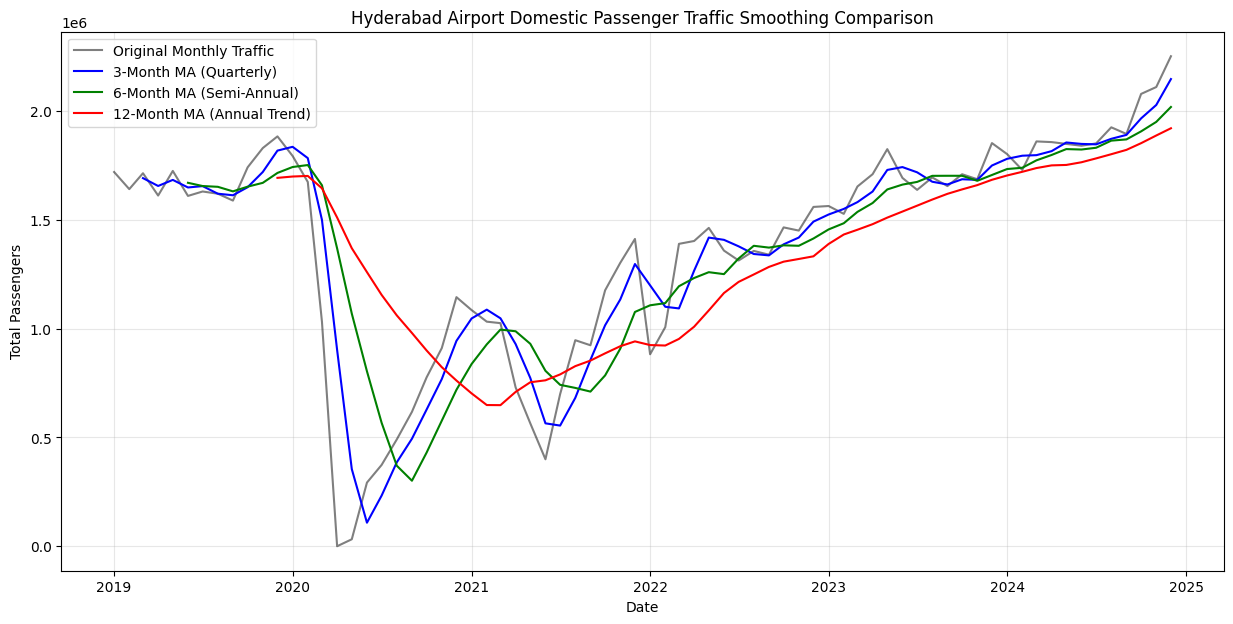

In [5]:
import matplotlib.pyplot as plt

# Calculate Moving Averages
ma3 = traffic_series.rolling(window=3).mean()
ma6 = traffic_series.rolling(window=6).mean()
ma12 = traffic_series.rolling(window=12).mean()

# Plot original series and Moving Averages
plt.figure(figsize=(15, 7))
plt.plot(traffic_series, label='Original Monthly Traffic', color='black', alpha=0.5)
plt.plot(ma3, label='3-Month MA (Quarterly)', color='blue')
plt.plot(ma6, label='6-Month MA (Semi-Annual)', color='green')
plt.plot(ma12, label='12-Month MA (Annual Trend)', color='red')

plt.title('Hyderabad Airport Domestic Passenger Traffic Smoothing Comparison')
plt.xlabel('Date')
plt.ylabel('Total Passengers')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [8]:
from statsmodels.tsa.stattools import adfuller

def check_stationarity(series, label):
    result = adfuller(series.dropna(), result_object=False)
    print(f"--- ADF Test: {label} ---")
    print(f"p-value: {result[1]:.4f}")
    if result[1] <= 0.05:
        print("Result: Stationary")
    else:
        print("Result: Non-Stationary")
    print("-" * 30)


# Test Original
check_stationarity(traffic_series, "Original Series")

# Test 1st Difference (Removes Trend)
traffic_diff = traffic_series.diff().dropna()
check_stationarity(traffic_diff, "1st Differenced Series")

# Test Seasonal Difference (Removes Annual Pattern)
# We difference by 12 because it is monthly data
traffic_seasonal_diff = traffic_diff.diff(12).dropna()
check_stationarity(traffic_seasonal_diff, "Seasonal + 1st Differenced Series")

--- ADF Test: Original Series ---
p-value: 0.2876
Result: Non-Stationary
------------------------------
--- ADF Test: 1st Differenced Series ---
p-value: 0.0018
Result: Stationary
------------------------------
--- ADF Test: Seasonal + 1st Differenced Series ---
p-value: 0.0000
Result: Stationary
------------------------------


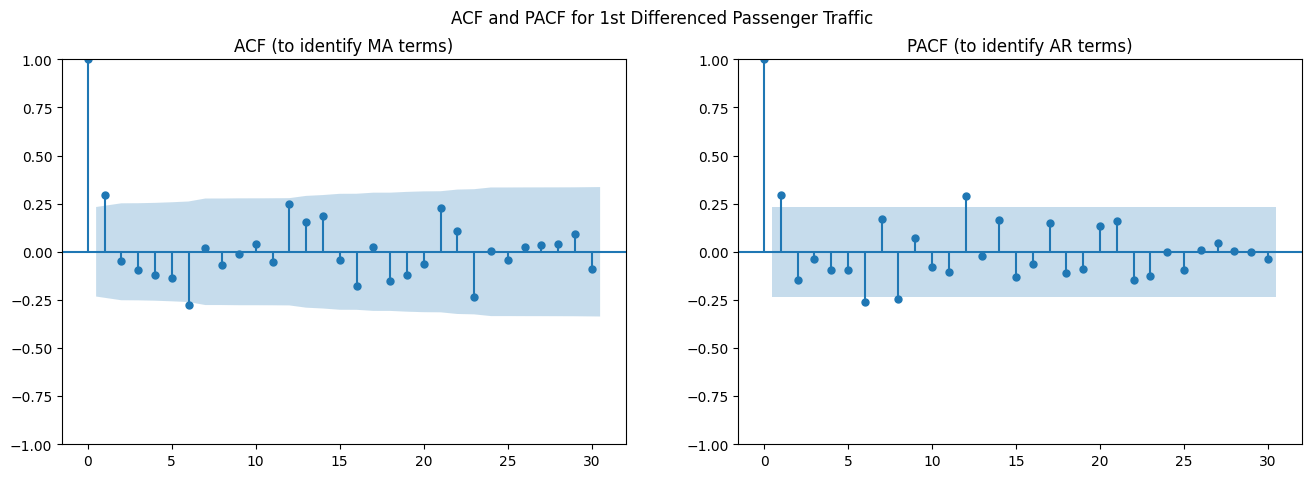

In [9]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Using the 1st Differenced Series as it is stationary
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

plot_acf(traffic_diff, lags=30, ax=ax1)
plot_pacf(traffic_diff, lags=30, ax=ax2)

ax1.set_title("ACF (to identify MA terms)")
ax2.set_title("PACF (to identify AR terms)")
plt.suptitle("ACF and PACF for 1st Differenced Passenger Traffic")
plt.show()

In [11]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

# Helper function to calculate metrics
def calculate_metrics(model_fit, actual, name):
    fitted = model_fit.fittedvalues
    # Skip early values due to differencing
    rmse = np.sqrt(mean_squared_error(actual[13:], fitted[13:]))
    mae = mean_absolute_error(actual[13:], fitted[13:])
    return {"Model": name, "AIC": model_fit.aic, "BIC": model_fit.bic, "RMSE": rmse, "MAE": mae}

results_list = []

# 1. AR(1) Model (on differenced data, so d=0)
model_ar = SARIMAX(traffic_diff, order=(1, 0, 0)).fit(disp=False)
results_list.append(calculate_metrics(model_ar, traffic_diff, "AR(1)"))

# 2. MA(1) Model (on differenced data, so d=0)
model_ma = SARIMAX(traffic_diff, order=(0, 0, 1)).fit(disp=False)
results_list.append(calculate_metrics(model_ma, traffic_diff, "MA(1)"))

# 3. ARMA(1,1) Model (on differenced data, so d=0)
model_arma = SARIMAX(traffic_diff, order=(1, 0, 1)).fit(disp=False)
results_list.append(calculate_metrics(model_arma, traffic_diff, "ARMA(1,1)"))

# 4. ARIMA(1,1,1) Model (on original data)
model_arima = SARIMAX(traffic_series, order=(1, 1, 1)).fit(disp=False)
# Note: RMSE/MAE for ARIMA/SARIMA will be larger because they are on actual passenger counts,
# while AR/MA/ARMA above were on differenced counts.
# For a fair comparison, let's fit them ALL on the traffic_series.

# --- RE-FITTING ALL ON ORIGINAL SERIES FOR FAIR COMPARISON ---
results_final = []
model_ar = SARIMAX(traffic_series, order=(1, 1, 0)).fit(disp=False)
results_final.append(calculate_metrics(model_ar, traffic_series, "AR(1)"))

model_ma = SARIMAX(traffic_series, order=(0, 1, 1)).fit(disp=False)
results_final.append(calculate_metrics(model_ma, traffic_series, "MA(1)"))

model_arma = SARIMAX(traffic_series, order=(1, 1, 1)).fit(disp=False)
results_final.append(calculate_metrics(model_arma, traffic_series, "ARMA(1,1)"))

model_arima = SARIMAX(traffic_series, order=(1, 1, 1)).fit(disp=False) # Same as ARMA(1,1,1)
results_final.append(calculate_metrics(model_arima, traffic_series, "ARIMA(1,1,1)"))

# 5. SARIMA(1,1,1)(1,1,1,12) Model
model_sarima = SARIMAX(traffic_series,
                        order=(1, 1, 1),
                        seasonal_order=(1, 1, 1, 12)).fit(disp=False)
results_final.append(calculate_metrics(model_sarima, traffic_series, "SARIMA"))

# Display comparison
comparison_df = pd.DataFrame(results_final)
print(comparison_df)

          Model          AIC          BIC           RMSE            MAE
0         AR(1)  1936.808790  1941.334150  209241.538648  134047.319785
1         MA(1)  1936.730702  1941.256062  208782.621379  133753.767309
2     ARMA(1,1)  1938.729387  1945.517426  208809.548014  133803.029727
3  ARIMA(1,1,1)  1938.729387  1945.517426  208809.548014  133803.029727
4        SARIMA  1642.784087  1653.171774  240888.786649  167305.998965


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


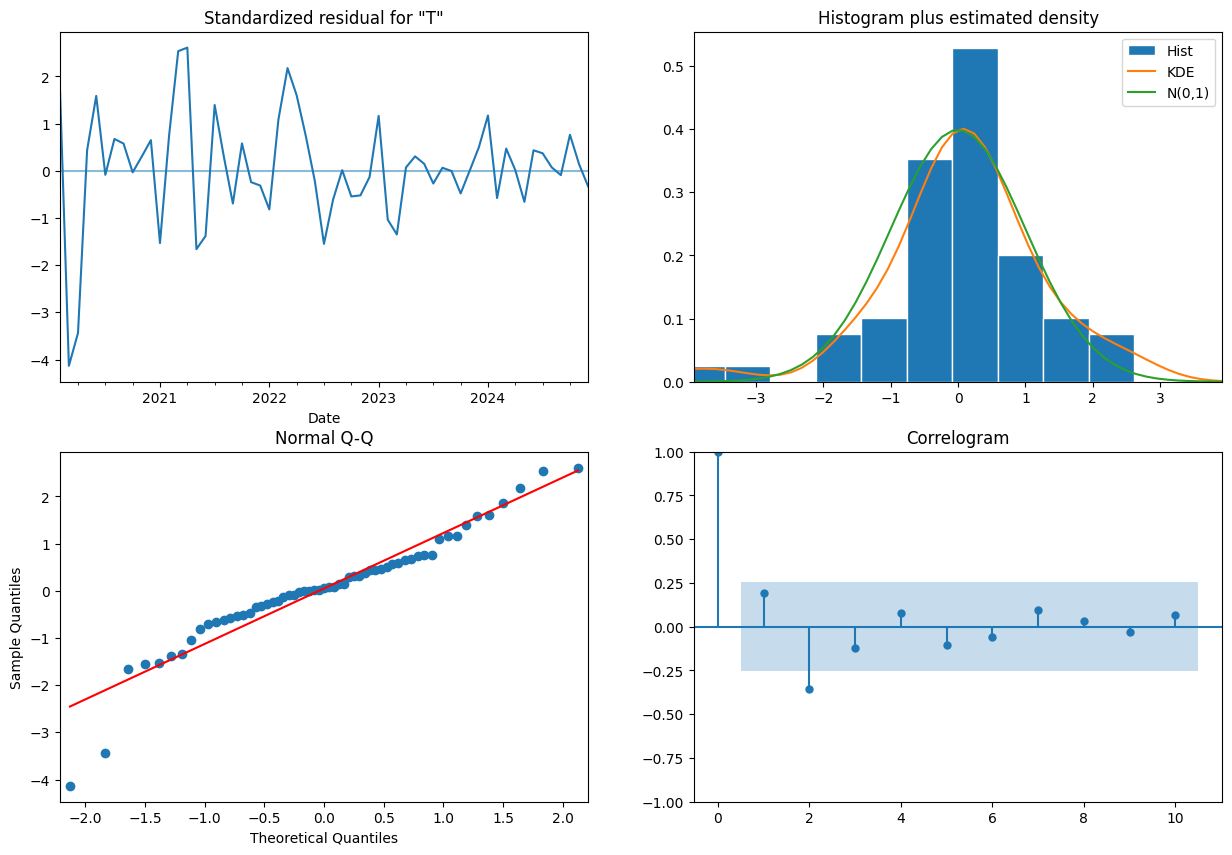

In [12]:
best_model = model_sarima

# Residual Plots
best_model.plot_diagnostics(figsize=(15, 10))
plt.show()

# Residual ACF
# from statsmodels.graphics.tsaplots import plot_acf
# plt.figure(figsize=(10, 4))
# plot_acf(best_model.resid, lags=30)
# plt.title("Autocorrelation of Residuals (Should be White Noise)")
# plt.show()

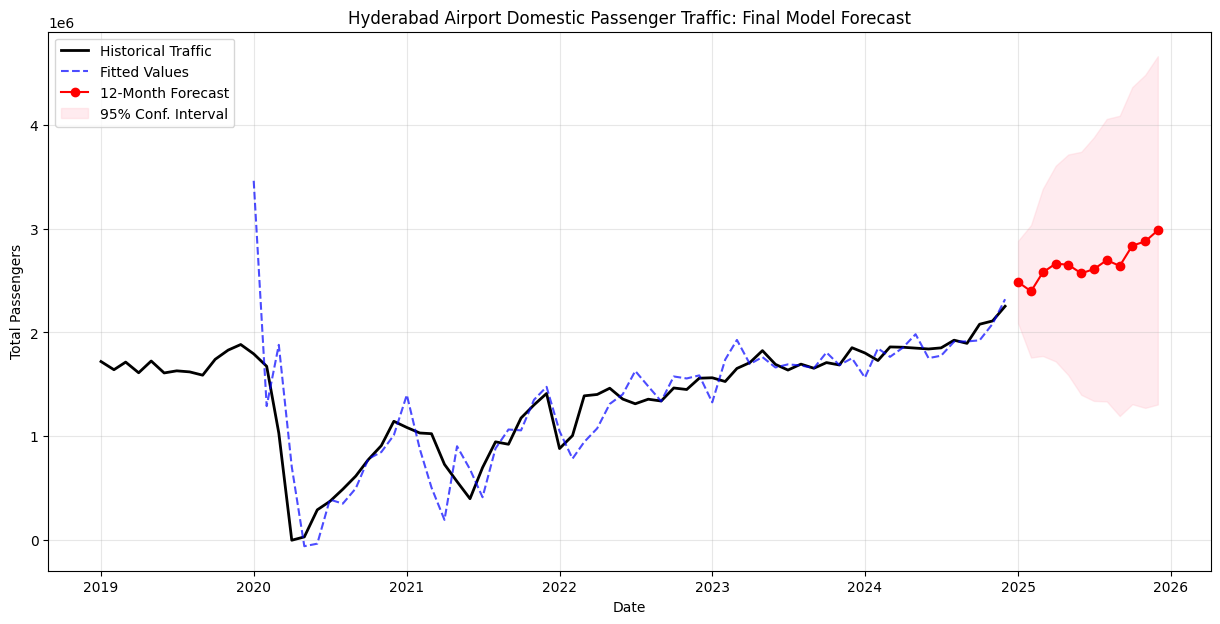

In [13]:
# Forecast next 12 months
forecast_steps = 12
forecast_obj = best_model.get_forecast(steps=forecast_steps)
forecast_mean = forecast_obj.predicted_mean
conf_int = forecast_obj.conf_int()

# Create forecast dates
forecast_dates = pd.date_range(start=traffic_series.index[-1] + pd.DateOffset(months=1),
                               periods=forecast_steps, freq='MS')
forecast_mean.index = forecast_dates
conf_int.index = forecast_dates

# Final Visualization
plt.figure(figsize=(15, 7))
plt.plot(traffic_series, label='Historical Traffic', color='black', linewidth=2)
plt.plot(best_model.fittedvalues[12:], label='Fitted Values', color='blue', linestyle='--', alpha=0.7)
plt.plot(forecast_mean, label='12-Month Forecast', color='red', marker='o')
plt.fill_between(forecast_dates, conf_int.iloc[:, 0], conf_int.iloc[:, 1], color='pink', alpha=0.3, label='95% Conf. Interval')

plt.title('Hyderabad Airport Domestic Passenger Traffic: Final Model Forecast')
plt.xlabel('Date')
plt.ylabel('Total Passengers')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()